# Breast Cancer Classification: Logistic Regression, SVM and PCA
### Independent academic project · Classical supervised learning · Kaggle CPU notebook

**Goal:** Compare **Logistic Regression** and **RBF Support Vector Machines**, with and without **Principal Component Analysis (PCA)**, to classify **malignant (positive = 1)** versus **benign (negative = 0)** using the **Wisconsin Diagnostic Breast Cancer** dataset.

The data have **569 cases and 30 numeric features extracted from cell-nucleus images**; this notebook does **not** classify raw mammograms or microscope images.

**Experimental plan:** 80/20 stratified hold-out split → 5-fold cross-validation *within training only* → select highest mean CV ROC-AUC → refit selected model on training data → evaluate **once** on the reserved hold-out set. Standardization and PCA stay **inside** the cross-validation pipelines to reduce leakage.

**Kaggle setup:** Python · CPU · Internet **Off** · no dataset attachment. Run the notebook from top to bottom. CSV files, charts and JSON metrics appear in `/kaggle/working/breast_cancer_ml_outputs` (or local `outputs/breast_cancer_ml_outputs`).

**Warning:** Research/education only. No patient identifiers or external clinical cohort are available, and predictions must not be used for medical decision-making.

## 1. Setup and reproducibility

The dataset is already included with scikit-learn as `load_breast_cancer`. We use a fixed split seed (**42**), fixed model hyperparameters, a **20% test set**, and **five-fold training cross-validation**.

In [1]:
from __future__ import annotations

import json
import platform
from collections import OrderedDict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42
POSITIVE_CLASS = "malignant"
CV_FOLDS = 5
TEST_SIZE = 0.20

from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # Avoid excessive BLAS threads on shared Kaggle CPUs
from IPython.display import display, Image

OUTPUT = (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd() / 'outputs') / 'breast_cancer_ml_outputs'
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Results location:', OUTPUT)
print('scikit-learn version:', sklearn.__version__)

Results location: /mnt/data/kaggle_notebooks_ready/outputs/breast_cancer_ml_outputs
scikit-learn version: 1.8.0


## 2. Load and inspect the biomedical dataset

**Label convention:** scikit-learn stores malignant as class 0 in its original dataset. We explicitly invert this: **1 = malignant, 0 = benign**, making sensitivity/recall refer to detecting malignancy. Features describe size, shape, and texture characteristics measured from digitized cell-nucleus images.

In [2]:
def get_data():
    """Return X, y and raw dataset metadata. y=1 denotes malignant."""
    dataset = load_breast_cancer(as_frame=True)
    X = dataset.data.copy()
    y = pd.Series((dataset.target == 0).astype(int), name="malignant", index=X.index)
    assert X.shape == (569, 30), "Unexpected dataset version"
    assert set(y.unique()) == {0, 1}
    assert int(y.sum()) == 212
    return X, y, dataset


def split_data(X, y):
    """Reproducible stratified split; retain original row indices for audit."""
    idx = np.arange(len(y))
    tr, te = train_test_split(idx, test_size=TEST_SIZE, random_state=SEED, stratify=y)
    return tr, te

In [3]:
X, y, dataset = get_data()
print(f'Dataset: {X.shape[0]} observations × {X.shape[1]} features')
print('Class counts (0=benign, 1=malignant):')
display(y.value_counts().sort_index().rename('count').to_frame())
display(X.head(3).iloc[:, :7])
train_idx, test_idx = split_data(X, y)
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
assert set(train_idx).isdisjoint(test_idx)
print('Train:', len(train_idx), '| Hold-out test:', len(test_idx))

Dataset: 569 observations × 30 features
Class counts (0=benign, 1=malignant):


,count
malignant,
0,357
1,212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974


Train: 455 | Hold-out test: 114


## 3. Models and 5-fold cross-validation

Four fixed candidates are compared: Logistic Regression, RBF SVM, Logistic Regression + PCA, and RBF SVM + PCA. We use `StandardScaler` because scale-sensitive models and PCA require compatible feature scales. The PCA variants retain enough training-fold variance to explain **95%** of variance.

The **primary selection criterion is mean ROC-AUC across training CV folds**. ROC-AUC measures ranking across possible thresholds; it should not be confused with test-set accuracy. No parameter is chosen by looking at the test labels.

In [4]:
def make_models():
    """Predetermined four comparison models. Scaling/PCA always inside Pipeline."""
    def logistic(pca=False):
        steps = [("scale", StandardScaler())]
        if pca:
            steps.append(("pca", PCA(n_components=0.95, svd_solver="full")))
        steps.append(("model", LogisticRegression(C=1.0, max_iter=3000, random_state=SEED)))
        return Pipeline(steps)

    def svm(pca=False):
        steps = [("scale", StandardScaler())]
        if pca:
            steps.append(("pca", PCA(n_components=0.95, svd_solver="full")))
        steps.append(("model", SVC(C=1.0, kernel="rbf", gamma="scale")))
        return Pipeline(steps)

    return OrderedDict([
        ("Logistic Regression", logistic()),
        ("RBF SVM", svm()),
        ("Logistic Regression + PCA", logistic(pca=True)),
        ("RBF SVM + PCA", svm(pca=True)),
    ])


def cross_validate_models(models, X_train, y_train):
    """Select models on training data only. PCA learns within each CV fold."""
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    scores = {
        "auc": "roc_auc", "balanced_accuracy": "balanced_accuracy",
        "f1_malignant": "f1", "accuracy": "accuracy",
    }
    rows = []
    for name, pipeline in models.items():
        result = cross_validate(pipeline, X_train, y_train, cv=cv,
                                scoring=scores, n_jobs=1, error_score="raise")
        row = {"model": name}
        for key in scores:
            row[f"cv_{key}_mean"] = float(np.mean(result[f"test_{key}"]))
            row[f"cv_{key}_std"] = float(np.std(result[f"test_{key}"], ddof=1))
        rows.append(row)
    return pd.DataFrame(rows)


def select_model(cv_table):
    """Choose highest CV ROC-AUC; tie-break CV balanced accuracy, then name."""
    ranked = cv_table.sort_values(
        by=["cv_auc_mean", "cv_balanced_accuracy_mean", "model"],
        ascending=[False, False, True], kind="mergesort",
    )
    return str(ranked.iloc[0]["model"])

In [5]:
models = make_models()
for name, model in models.items():
    print(name, '| steps:', ' → '.join(model.named_steps.keys()))
cv_preview = cross_validate_models(models, X_train, y_train)
display(cv_preview[['model','cv_auc_mean','cv_auc_std','cv_accuracy_mean']].round(4))
print('CV-selected model:', select_model(cv_preview))

Logistic Regression | steps: scale → model
RBF SVM | steps: scale → model
Logistic Regression + PCA | steps: scale → pca → model
RBF SVM + PCA | steps: scale → pca → model


,model,cv_auc_mean,cv_auc_std,cv_accuracy_mean
0,Logistic Regression,0.9958,0.0052,0.9736
1,RBF SVM,0.9949,0.0056,0.9714
2,Logistic Regression + PCA,0.9943,0.0061,0.9758
3,RBF SVM + PCA,0.9947,0.0054,0.9714


CV-selected model: Logistic Regression


## 4. Hold-out metrics and failure analysis

After selecting by cross-validation, we refit on **all training observations** and test once. We use ROC-AUC, accuracy, balanced accuracy, precision, recall/sensitivity, specificity, F1-score and a confusion matrix. **Missing a malignant case is a false negative (FN)**, a material concern even when overall accuracy is high.

In [6]:
def eval_selected(estimator, X_test, y_test):
    """Evaluate exactly one selected estimator on previously untouched test data."""
    pred = estimator.predict(X_test)
    score = estimator.decision_function(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    m = {
        "test_n": int(len(y_test)),
        "accuracy": float(accuracy_score(y_test, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test, pred)),
        "roc_auc": float(roc_auc_score(y_test, score)),
        "precision_malignant": float(precision_score(y_test, pred, zero_division=0)),
        "recall_malignant_sensitivity": float(recall_score(y_test, pred, zero_division=0)),
        "f1_malignant": float(f1_score(y_test, pred, zero_division=0)),
        "specificity_benign": float(tn / (tn + fp)),
        "true_benign": int(tn),
        "false_malignant": int(fp),
        "missed_malignant": int(fn),
        "correct_malignant": int(tp),
    }
    return m, np.asarray(pred), np.asarray(score)

## 5. Figures, exported files, and end-to-end experiment

This reproduces the original implementation and saves: class distribution, CV comparison, PCA explained variance, test confusion matrix, test ROC curve, indices of the held-out cases, individual test predictions, and machine-readable metrics.

In [7]:
def plot_dataset(y, out):
    fig, ax = plt.subplots(figsize=(5.9, 4.1))
    counts = [int((y == 0).sum()), int((y == 1).sum())]
    bars = ax.bar(["Benign (0)", "Malignant (1)"], counts, color=["#7199c0", "#d77e72"])
    ax.bar_label(bars, padding=3)
    ax.set_ylim(0, max(counts)*1.18)
    ax.set_ylabel("Number of observations")
    ax.set_title("Dataset class distribution")
    fig.tight_layout(); fig.savefig(out, dpi=170); plt.close(fig)


def plot_cv(cv_table, out):
    d = cv_table.sort_values("cv_auc_mean", ascending=True)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    y_pos = np.arange(len(d))
    ax.errorbar(d["cv_auc_mean"], y_pos, xerr=d["cv_auc_std"],
                fmt="o", ms=8, color="#3979a8", ecolor="#577a91", capsize=5,
                linewidth=2)
    ax.set_yticks(y_pos, d["model"])
    ax.set_xlabel("Mean 5-fold cross-validation ROC-AUC (± 1 SD)")
    ax.set_xlim(max(0.0, float(d["cv_auc_mean"].min())-0.02), 1.008)
    ax.set_title("Model comparison: training folds only")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout(); fig.savefig(out, dpi=170); plt.close(fig)


def plot_cm(metrics, out):
    matrix = np.array([[metrics["true_benign"], metrics["false_malignant"]],
                       [metrics["missed_malignant"], metrics["correct_malignant"]]])
    fig, ax = plt.subplots(figsize=(5.5, 4.6))
    im = ax.imshow(matrix, cmap="Blues", vmin=0)
    ax.set_xticks([0, 1], ["Benign", "Malignant"])
    ax.set_yticks([0, 1], ["Benign", "Malignant"])
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    ax.set_title("Untouched test: selected model")
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, str(value), ha="center", va="center",
                color="white" if im.norm(value)>0.5 else "black", fontsize=16)
    fig.tight_layout(); fig.savefig(out, dpi=170); plt.close(fig)


def plot_roc(y_test, test_scores, metrics, out):
    fpr, tpr, _ = roc_curve(y_test, test_scores, pos_label=1)
    fig, ax = plt.subplots(figsize=(5.8, 4.8))
    ax.plot(fpr, tpr, lw=2, label=f"Selected model (AUC={metrics['roc_auc']:.3f})")
    ax.plot([0, 1], [0, 1], "--", lw=1, color="gray", label="Chance")
    ax.set(xlim=(0, 1), ylim=(0, 1.01), xlabel="False-positive rate",
           ylabel="True-positive rate (sensitivity)", title="Held-out test ROC curve")
    ax.legend(loc="lower right"); ax.grid(alpha=0.22)
    fig.tight_layout(); fig.savefig(out, dpi=170); plt.close(fig)


def plot_pca(X_train, out):
    """Separate descriptive PCA on train only; not used to select model."""
    X_std = StandardScaler().fit_transform(X_train)
    pca = PCA().fit(X_std)
    cum = np.cumsum(pca.explained_variance_ratio_)
    n95 = int(np.searchsorted(cum, 0.95) + 1)
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    ax.plot(np.arange(1, len(cum) + 1), cum, marker="o", ms=3)
    ax.axhline(0.95, color="#c46e61", ls="--", label="95% threshold")
    ax.axvline(n95, color="#669a73", ls=":", label=f"{n95} components reach 95%")
    ax.set(xlabel="Number of principal components", ylabel="Cumulative explained variance",
           title="PCA of standardized training features", ylim=(0, 1.03))
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout(); fig.savefig(out, dpi=170); plt.close(fig)
    return n95

In [8]:
def run_experiment(output_dir):
    """End-to-end deterministic benchmark. Writes figures, tables and metadata."""
    root = Path(output_dir)
    results_dir = root / "results"; figures_dir = root / "figures"
    results_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    X, y, _ = get_data()
    tr, te = split_data(X, y)
    X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    assert set(tr).isdisjoint(set(te))
    assert len(tr)+len(te)==len(y)

    splits = pd.DataFrame({"original_row_index": np.arange(len(X)), "split": "test"})
    splits.loc[tr, "split"] = "train"
    splits.to_csv(results_dir / "split_indices.csv", index=False)

    models = make_models()
    cv_table = cross_validate_models(models, X_tr, y_tr)
    cv_table.to_csv(results_dir / "cv_results.csv", index=False, float_format="%.8f")
    selected_name = select_model(cv_table)
    selected = models[selected_name]
    selected.fit(X_tr, y_tr)  # fitted only after cross-validation model selection
    metrics, preds, test_scores = eval_selected(selected, X_te, y_te)
    metrics["selected_model"] = selected_name
    (results_dir / "test_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
    pd.DataFrame([metrics]).to_csv(results_dir / "test_results.csv", index=False)
    pd.DataFrame({"original_row_index": te, "true_malignant": y_te.to_numpy(),
                  "predicted_malignant": preds, "model_decision_score": test_scores}).to_csv(
        results_dir / "test_predictions.csv", index=False, float_format="%.8f")

    n95 = plot_pca(X_tr, figures_dir / "pca_explained_variance.png")
    plot_dataset(y, figures_dir / "dataset_distribution.png")
    plot_cv(cv_table, figures_dir / "cross_validation_comparison.png")
    plot_cm(metrics, figures_dir / "test_confusion_matrix.png")
    plot_roc(y_te, test_scores, metrics, figures_dir / "test_roc_curve.png")
    summary = {
        "dataset": "Wisconsin Diagnostic Breast Cancer (scikit-learn built-in)",
        "samples": int(len(X)), "features": int(X.shape[1]),
        "malignant_positive_class": 1, "malignant_samples": int(y.sum()),
        "benign_samples": int((y==0).sum()),
        "train_n": int(len(tr)), "test_n": int(len(te)),
        "train_malignant": int(y_tr.sum()), "test_malignant": int(y_te.sum()),
        "random_seed": SEED, "test_fraction": TEST_SIZE, "cv_folds": CV_FOLDS,
        "pca_train_components_95percent": n95, "selected_model": selected_name,
        "python_version": platform.python_version(), "scikit_learn_version": sklearn.__version__,
        "feature_scaling_and_PCA_within_CV_pipelines": True,
        "test_reserved_until_selection": True,
        "patient_level_splits_verified": False,
    }
    (results_dir / "dataset_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
    return cv_table, metrics, summary

In [9]:
cv_table, test_metrics, dataset_summary = run_experiment(OUTPUT)
print('Training-only CV results:')
display(cv_table[['model', 'cv_auc_mean', 'cv_accuracy_mean', 'cv_balanced_accuracy_mean']].round(4))
print('Selected model:', test_metrics['selected_model'])
print('Held-out test metrics:')
display(pd.DataFrame([test_metrics]).T.rename(columns={0: 'value'}))

Training-only CV results:


,model,cv_auc_mean,cv_accuracy_mean,cv_balanced_accuracy_mean
0,Logistic Regression,0.9958,0.9736,0.9695
1,RBF SVM,0.9949,0.9714,0.9665
2,Logistic Regression + PCA,0.9943,0.9758,0.9712
3,RBF SVM + PCA,0.9947,0.9714,0.9665


Selected model: Logistic Regression
Held-out test metrics:


,value
test_n,114
accuracy,0.964912
balanced_accuracy,0.957341
roc_auc,0.996032
precision_malignant,0.975
recall_malignant_sensitivity,0.928571
f1_malignant,0.95122
specificity_benign,0.986111
true_benign,71
false_malignant,1


## 6. Charts

The confusion matrix uses the class ordering **benign (0)**, **malignant (1)**. Pay particular attention to the **missed malignant** (false-negative) cell.

Figure: dataset_distribution.png


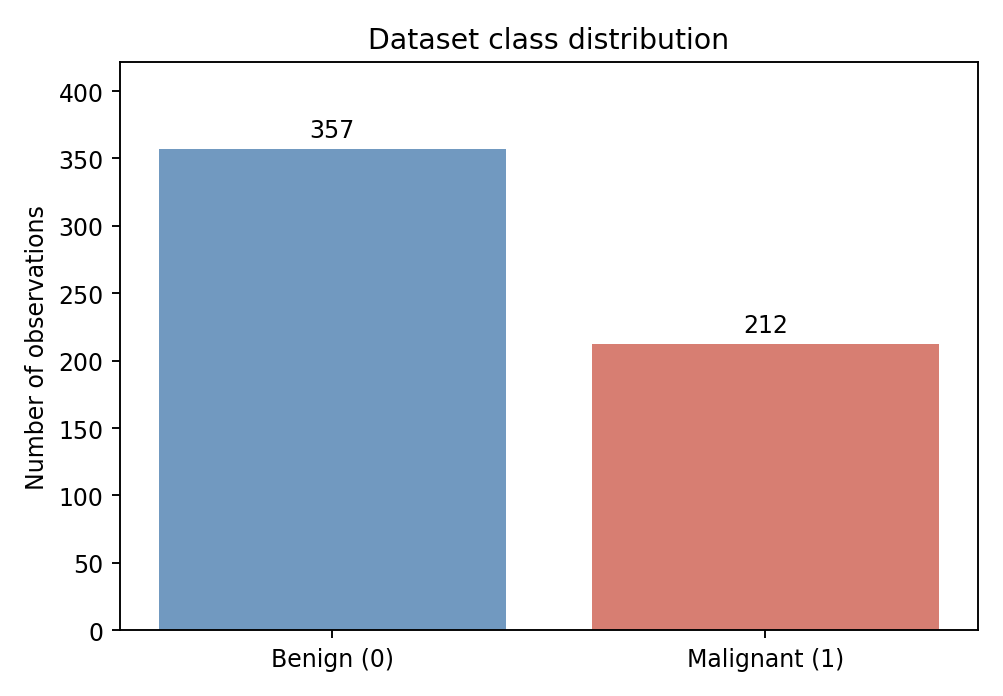

Figure: cross_validation_comparison.png


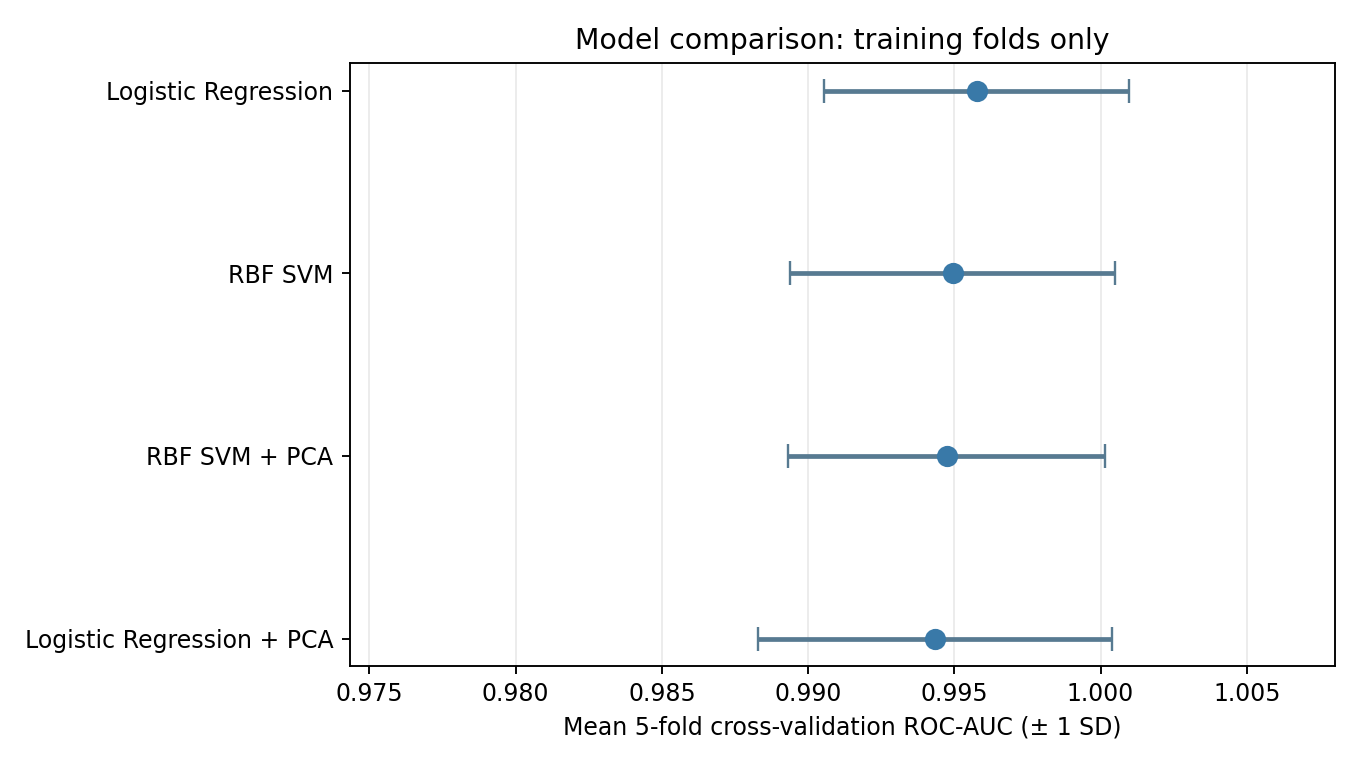

Figure: pca_explained_variance.png


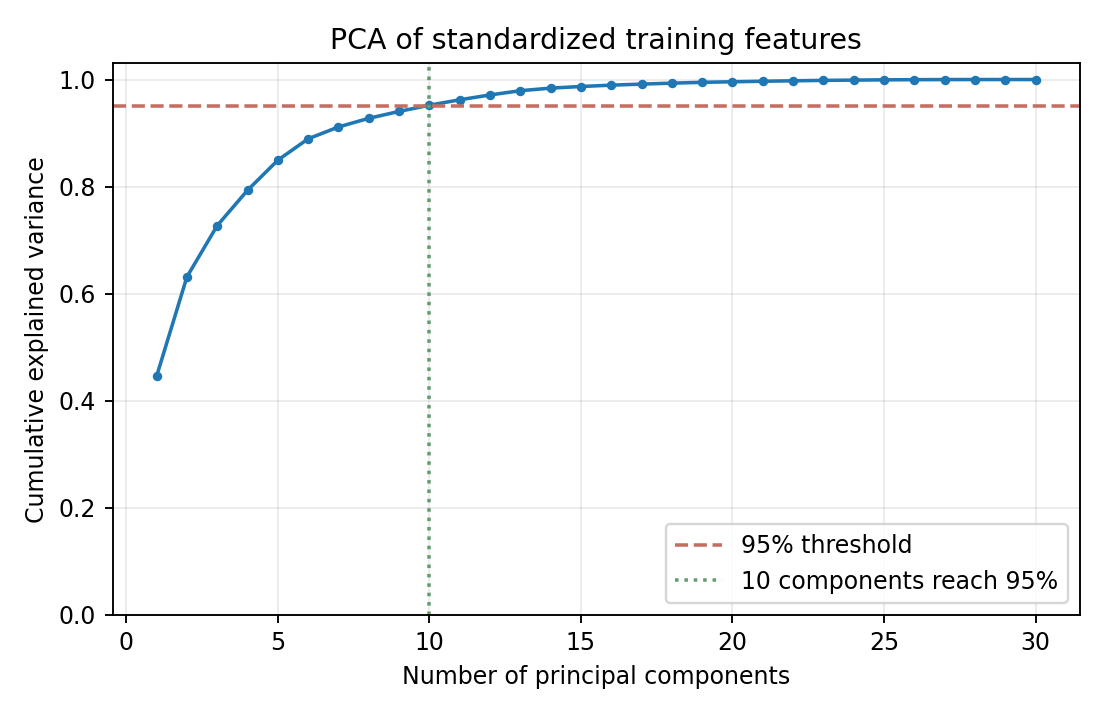

Figure: test_confusion_matrix.png


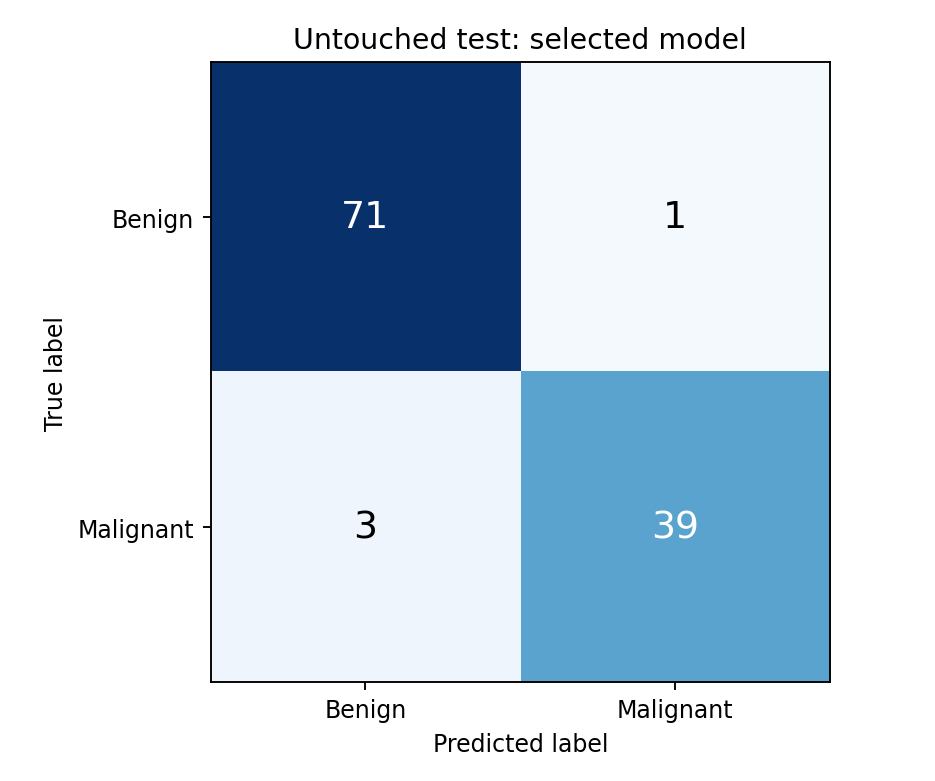

Figure: test_roc_curve.png


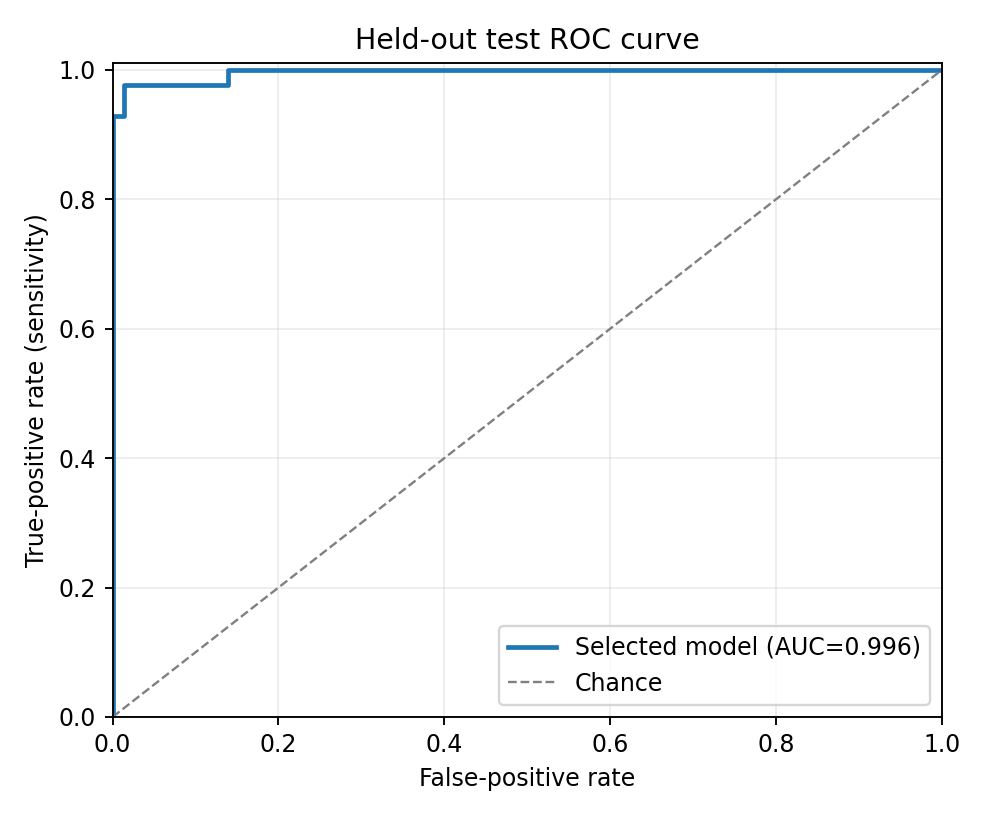

In [10]:
for figure_name in [
    'dataset_distribution.png',
    'cross_validation_comparison.png',
    'pca_explained_variance.png',
    'test_confusion_matrix.png',
    'test_roc_curve.png',
]:
    print('Figure:', figure_name)
    display(Image(filename=str(OUTPUT / 'figures' / figure_name)))

## 7. Sanity checks and interpretation

Cross-validation accuracy and CV ROC-AUC can rank models differently. Higher-dimensional features do not always benefit from PCA; PCA retains **variance**, not necessarily the most predictive information. These results are from a single dataset and hold-out split, and may not transfer to new hospitals or patient populations.

The original dataset does **not** supply patient IDs for subject-wise splitting, so this is **not** a patient-level external validation study. The test set is independent only in the **row-split** sense.

In [11]:
assert len(train_idx) == 455 and len(test_idx) == 114
assert set(train_idx).isdisjoint(test_idx)
assert len(cv_table) == 4
assert test_metrics['true_benign'] + test_metrics['false_malignant'] + test_metrics['missed_malignant'] + test_metrics['correct_malignant'] == len(test_idx)
assert 0 <= test_metrics['roc_auc'] <= 1
print('PASS: stratified hold-out, 4 models, complete confusion matrix, valid ROC-AUC')
print('Output files:')
for p in sorted(OUTPUT.rglob('*')):
    if p.is_file(): print('-', p.relative_to(OUTPUT))

PASS: stratified hold-out, 4 models, complete confusion matrix, valid ROC-AUC
Output files:
- figures/cross_validation_comparison.png
- figures/dataset_distribution.png
- figures/pca_explained_variance.png
- figures/test_confusion_matrix.png
- figures/test_roc_curve.png
- results/cv_results.csv
- results/dataset_summary.json
- results/split_indices.csv
- results/test_metrics.json
- results/test_predictions.csv
- results/test_results.csv


## 8. Conclusion, provenance and limitations

This project presents an introductory, reproducible classical machine-learning comparison. It uses **feature descriptors extracted from digitized fine-needle aspirate samples**, not direct image inference, and does not establish clinical safety or generalizability.

The script tests four specified workflows; it does not conduct an exhaustive hyperparameter search. The selected model is chosen using cross-validation, and the held-out test is evaluated once. The number of malignant false negatives matters more for clinical safety than accuracy alone, but a coursework benchmark is **not** a clinical evaluation.

**Dataset reference:** UCI Machine Learning Repository, *Breast Cancer Wisconsin (Diagnostic)*; accessible through scikit-learn `load_breast_cancer`. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

**CV title:** *Breast Cancer Classification Using SVM and Logistic Regression* — Independent Academic Project (2026).